In [1]:
try:
    import google.colab  # noqa: F401

    # specify the version of DataEval (==X.XX.X) for versions other than the latest
    %pip install -q dataeval "dataeval-plots>=0.0.20" "maite-datasets[hf]>=0.0.25"
except Exception:
    pass

In [2]:
import warnings

import dataeval_plots as dep
import numpy as np
import polars as pl
import torch
from IPython.display import display
from maite_datasets.multiobject_tracking import VisDroneMOT
from torchvision.models import ResNet18_Weights, resnet18

from dataeval import Embeddings
from dataeval.config import set_device
from dataeval.core import track_switches
from dataeval.data import DetectionCrops, Indices, SequenceFrames, View
from dataeval.exceptions import ExperimentalWarning
from dataeval.extractors import TorchExtractor

set_device("cuda" if torch.cuda.is_available() else "cpu")
# track_switches is experimental.
warnings.filterwarnings("ignore", category=ExperimentalWarning)

In [3]:
dataset = VisDroneMOT(root="./data", image_set="val", download=True)
frames = SequenceFrames(View(dataset, Indices([6])))
print(f"{frames[0][2]['source_id']}: {len(frames)} frames")

uav0000339_00001_v: 275 frames


In [4]:
# TEST ASSERTION CELL ###
assert frames[0][2]["source_id"] == "uav0000339_00001_v"
assert len(frames) == 275

In [5]:
crops = DetectionCrops(frames, min_size=16, square="pad")
weights = ResNet18_Weights.DEFAULT
extractor = TorchExtractor(
    resnet18(weights=weights, progress=False), transforms=weights.transforms(), layer_name="avgpool"
)
embeddings = Embeddings(crops, extractor=extractor, batch_size=64)
print(f"{len(crops)} crops, {crops.n_dropped} dropped")

11286 crops, 742 dropped


In [6]:
video, frame = frames.frame_map[crops.item_indices].T
result = track_switches(embeddings, crops.track_ids, frame, video, boxes=crops.boxes, labels=crops.labels)
encounters = pl.DataFrame(result)
print(f"{encounters.height} encounters, {encounters['switch_score'].is_not_nan().sum()} scored")
display(encounters.filter(pl.col("flagged")).select("label", "track_a", "track_b", "frame", "switch_score"))

64 encounters, 62 scored


label,track_a,track_b,frame,switch_score
i64,i64,i64,i64,f64
1,27,28,107,0.51207
0,77,79,123,0.035109


In [7]:
# TEST ASSERTION CELL ###
assert (len(crops), len(np.unique(crops.track_ids))) == (11286, 71)
assert (crops.track_ids >= 0).all()  # so np.unique counts tracks only
# Two encounters are too near a track's end to score.
assert (encounters.height, int(encounters["switch_score"].is_not_nan().sum())) == (64, 62)
# The third score is about -0.025, far from 0 against the 1e-4 difference between a CPU and a GPU run.
assert int(encounters["flagged"].sum()) == 2
assert encounters["switch_score"][2] < -0.01
top = encounters.row(0, named=True)
assert (top["track_a"], top["track_b"], top["flagged"]) == (27, 28, True)

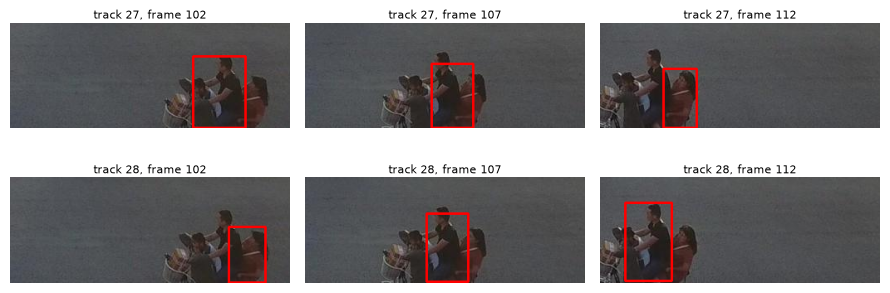

In [8]:
top = encounters.row(0, named=True)
pair = (top["track_a"], top["track_b"])
shown = [top["frame"] - 5, top["frame"], top["frame"] + 5]
here = video == top["item_index"]
row = {(t, f): np.flatnonzero(here & (crops.track_ids == t) & (frame == f))[0] for t in pair for f in shown}
corners = crops.boxes[list(row.values())]
height, width = np.asarray(frames[int(crops.item_indices[top["row_a"]])][0]).shape[-2:]
area = (
    max(int(corners[:, 0].min()) - 30, 0),
    max(int(corners[:, 1].min()) - 30, 0),
    min(int(corners[:, 2].max()) + 30, width),
    min(int(corners[:, 3].max()) + 30, height),
)
dep.plot(
    frames,
    indices=crops.item_indices[list(row.values())].tolist(),
    images_per_row=3,
    titles=[f"track {t}, frame {f}" for t, f in row],
    boxes=[[box] for box in corners.tolist()],
    region=area,
    box_color="red",
    figsize=(9, 3.6),
)

In [9]:
# TEST ASSERTION CELL ###
assert shown == [102, 107, 112]  # the frames the text names
centers = {key: (crops.boxes[r][0] + crops.boxes[r][2]) / 2 for key, r in row.items()}
# The two boxes cross.
assert centers[27, 102] < centers[28, 102]
assert centers[27, 112] > centers[28, 112]